In [1]:
import sys

print(sys.version)
print(sys.executable)

3.12.14 (main, Sep  1 2026, 14:17:39) [MSC v.1944 64 bit (AMD64)]
C:\crawl data\.venv\Scripts\python.exe


# THÀNH VIÊN 2 – PHÂN TÍCH KHÁM PHÁ DỮ LIỆU

## Phân tích thị trường tuyển dụng ngành Data

### Nội dung thực hiện
- 2.2. Exploratory Data Analysis (EDA)
- 2.3. K-Means Clustering
- 2.4. Association Rules (Apriori / FP-Growth)

Nguồn dữ liệu: data/clean_data.csv

In [2]:
import warnings
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# seaborn 0.13.2 (bản mới nhất trên PyPI) vẫn truyền `vert=` vào ax.bxp()
# bên trong sns.boxplot, trong khi Matplotlib >= 3.10 đã thay bằng `orientation=`.
# Đây là cảnh báo nội bộ của seaborn, KHÔNG ảnh hưởng tới biểu đồ, nên chỉ ẩn
# đúng cảnh báo này (mọi cảnh báo khác vẫn hiển thị bình thường).
# - Matplotlib 3.10: PendingDeprecationWarning
# - Matplotlib >= 3.11: MatplotlibDeprecationWarning (lớp con của DeprecationWarning)
for _category in (DeprecationWarning, PendingDeprecationWarning):
    warnings.filterwarnings("ignore", message=r"vert: bool", category=_category)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

In [3]:
# Tìm data/clean_data.csv dù notebook được mở từ thư mục gốc hay từ notebooks/
# (dùng pathlib nên chạy giống nhau trên Windows, macOS và Linux)
DATA_FILE = Path("data") / "clean_data.csv"

data_path = next(
    (base / DATA_FILE for base in (Path.cwd(), *Path.cwd().parents)
     if (base / DATA_FILE).exists()),
    None
)

if data_path is None:
    raise FileNotFoundError(
        f"Không tìm thấy {DATA_FILE}. Hãy chạy notebook bên trong thư mục dự án."
    )

# utf-8-sig: đọc đúng file CSV có BOM do step_02_clean_data.py xuất ra
df = pd.read_csv(data_path, encoding="utf-8-sig")

print("Số tin tuyển dụng:", df.shape[0])
print("Số thuộc tính:", df.shape[1])

df.head()

Số tin tuyển dụng: 1547
Số thuộc tính: 85


,Job_ID,Site,Tieu_De,Cong_Ty,Nhom_Nganh_Data,Dia_Diem_Goc,Dia_Diem_Chuan,Hinh_Thuc_Lam_Viec_Goc,Mo_Hinh_Lam_Viec,Kinh_Nghiem_Goc,So_Nam_Kinh_Nghiem,Cap_Bac,Muc_Luong_Goc,Trang_Thai_Luong,Luong_Min,Luong_Max,Luong_Trung_Binh,Luong_Trung_Binh_Imputed,Khoang_Luong_Phan_Lop,Danh_Sach_Ky_Nang,So_Luong_Ky_Nang,Mo_Ta_Cong_Viec,Mo_Ta_Lam_Sach,URL_Goc,Timestamp,Skill_Python,Skill_SQL,Skill_R,Skill_Scala,Skill_Java,Skill_C_Cpp,Skill_JavaScript,Skill_Bash_Shell,Skill_PowerBI,Skill_Tableau,Skill_Looker,Skill_Excel,Skill_Statistics,Skill_AB_Testing,Skill_Data_Storytelling,Skill_Spark,Skill_Hadoop,Skill_Kafka,Skill_Airflow,Skill_dbt,Skill_ETL,Skill_Data_Warehouse,Skill_Data_Lake,Skill_Data_Modeling,Skill_Machine_Learning,Skill_Deep_Learning,Skill_Pandas,Skill_NumPy,Skill_Scikit_Learn,Skill_PyTorch,Skill_TensorFlow,Skill_NLP,Skill_Computer_Vision,Skill_LLM_GenAI,Skill_MLOps,Skill_PostgreSQL,Skill_MySQL,Skill_SQL_Server,Skill_Oracle,Skill_MongoDB,Skill_Redis,Skill_Elasticsearch,Skill_BigQuery,Skill_Snowflake,Skill_Databricks,Skill_Redshift,Skill_Cloud_AWS,Skill_Cloud_Azure,Skill_Cloud_GCP,Skill_Docker,Skill_Kubernetes,Skill_Git,Skill_Linux,Skill_CI_CD,Skill_English,Skill_Communication,Skill_Problem_Solving,Skill_Teamwork,Skill_Agile_Scrum,Skill_Data_Governance
0,DATA_0001,topcv,Chuyên Viên Dữ Liệu Lớn (Big Data),ProNgân hàng TMCP Đông Nam Á - SEABANK,Data Engineer / Big Data,Hà Nội,Hà Nội,On-site (Toàn thời gian),On-site,1 năm,1.0,Junior,Thoả thuận,Thoa_Thuan,NaN,NaN,NaN,19.50,15M - 30M,Python; SQL; Scala; PowerBI; Tableau; Looker; ...,21,## Company\r\n\r\nSoutheast Asia Commercial Jo...,## company southeast asia commercial joint sto...,https://www.topcv.vn/viec-lam/chuyen-vien-du-l...,2026-11-13 10:45:00,1,1,0,1,0,0,0,0,1,1,1,0,0,0,1,1,1,1,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,1,1,1,1,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0
1,DATA_0002,topdev,DATA ENGINEER / DATA PLATFORM ENGINEER,CÔNG TY TNHH AZIWORLD,Data Engineer / Big Data,Việt Nam,Khác,On-site (Toàn thời gian),On-site,3 years of experience,3.0,Middle,Login to view salary,Thoa_Thuan,NaN,NaN,NaN,26.50,15M - 30M,Python; SQL; Looker; Data_Storytelling; Spark;...,25,## Company\r\n\r\nAzIWorld Company Limited (CÔ...,## company aziworld company limited tnhh aziwo...,https://topdev.vn/detail-jobs/data-engineer-da...,2026-10-17 09:00:00,1,1,0,0,0,0,0,0,0,0,1,0,0,0,1,1,0,1,1,1,1,1,1,1,0,0,0,0,0,0,0,0,0,1,1,1,0,1,0,1,1,0,0,0,1,0,1,0,0,1,1,0,0,1,1,0,0,0,0,1
2,DATA_0003,topcv,Lead Data Engineer,CÔNG TY CỔ PHẦN CÔNG NGHỆ SICIX,Data Engineer / Big Data,Hà Nội,Hà Nội,On-site (Toàn thời gian),On-site,3 năm,6.0,Lead,20 - 40 triệu,Co_Cong_Bo,20.0,40.0,30.00,30.00,15M - 30M,Python; SQL; Scala; Java; Statistics; Data_Sto...,24,## Company\r\n\r\nSICIX Technology Joint Stock...,## company sicix technology joint stock compan...,https://www.topcv.vn/viec-lam/lead-data-engine...,2026-11-13 10:45:00,1,1,0,1,1,0,0,0,0,0,0,0,1,0,1,1,1,1,0,1,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,1,1,0,1,1,0,1,1,1,1,0,0,0,0,0,0,0,0,0,0,1
3,DATA_0004,vietnamworks,Database Administrator,Navigos Group,Database / Data Platform & Ops,Hồ Chí Minh,TP.HCM,On-site (Toàn thời gian),On-site,Experienced (non-manager),2.5,Middle,"$ 1,000-1,500 /tháng",Co_Cong_Bo,25.4,38.1,31.75,31.75,Trên 30M,Python; SQL; Bash_Shell; PowerBI; Tableau; Loo...,26,## Company\r\n\r\nNavigos Group is a technolog...,## company navigos group technology company op...,https://www.vietnamworks.com/database-administ...,2026-10-23 08:01:45,1,1,0,0,0,0,0,1,1,1,1,0,0,0,1,0,0,1,1,1,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,1,1,1,0,1,1,1,1,1,0,0,0,0,0,1,1,1,1,0,0,1,0,0,0,1
4,DATA_0005,vietnamworks,Trưởng Phòng Kiến Trúc Và Nền Tảng Dữ Liệu,Ngân Hàng TMCP Phương Đông ( OCB ),Data Engineer / Big Data,Hồ Chí Minh,TP.HCM,On-site (Full-time),On-site,Manager,6.0,Lead,Thương lượng,Thoa_Thuan,NaN,NaN,NaN,30.00,15M - 30M,Python; SQL; Data_Storytelling; Spark; Hadoop;...,24,## Company\r\n\r\nOrient Commercial Joint Stoc...,## company orient commercial joint stock bank ...,https://www.vietnamworks.com/t

## 2.2. Phân tích khám phá dữ liệu (EDA)

### 2.2.1. Thống kê mô tả và kiểm tra dữ liệu

In [4]:
print("Số lượng tin tuyển dụng theo nhóm ngành:")

df["Nhom_Nganh_Data"].value_counts()


Số lượng tin tuyển dụng theo nhóm ngành:


Nhom_Nganh_Data
Database / Data Platform & Ops    527
Data Engineer / Big Data          323
Data Scientist / AI & ML          308
Data Analyst / BI                 296
Data-Driven Software Engineer      93
Name: count, dtype: int64

In [5]:
print("Trạng thái mức lương:")
print(df["Trang_Thai_Luong"].value_counts())

print("\nThống kê mức lương:")
print(df["Luong_Trung_Binh"].describe())

print("\nSố mức lương bị thiếu:")
print(df["Luong_Trung_Binh"].isna().sum())

Trạng thái mức lương:
Trang_Thai_Luong
Thoa_Thuan    1156
Co_Cong_Bo     391
Name: count, dtype: int64

Thống kê mức lương:
count    391.000000
mean      28.041253
std       16.709884
min        3.400000
25%       19.000000
50%       25.500000
75%       35.000000
max      215.900000
Name: Luong_Trung_Binh, dtype: float64

Số mức lương bị thiếu:
1156


In [6]:
skill_cols = [
    col for col in df.columns
    if col.startswith("Skill_")
]

print("Số cột kỹ năng:", len(skill_cols))

print("Các giá trị của kỹ năng:")
print(np.unique(df[skill_cols].to_numpy()))

Số cột kỹ năng: 60
Các giá trị của kỹ năng:
[0 1]


### 2.2.2. Phân phối mức lương

- Khảo sát phân phối mức lương của thị trường ngành Data.
- Xác định khoảng lương tập trung phổ biến.
- So sánh mức lương trung bình và trung vị.
- Nhận diện các giá trị lương bất thường.

Phân tích sử dụng 391 tin tuyển dụng có công bố mức lương.

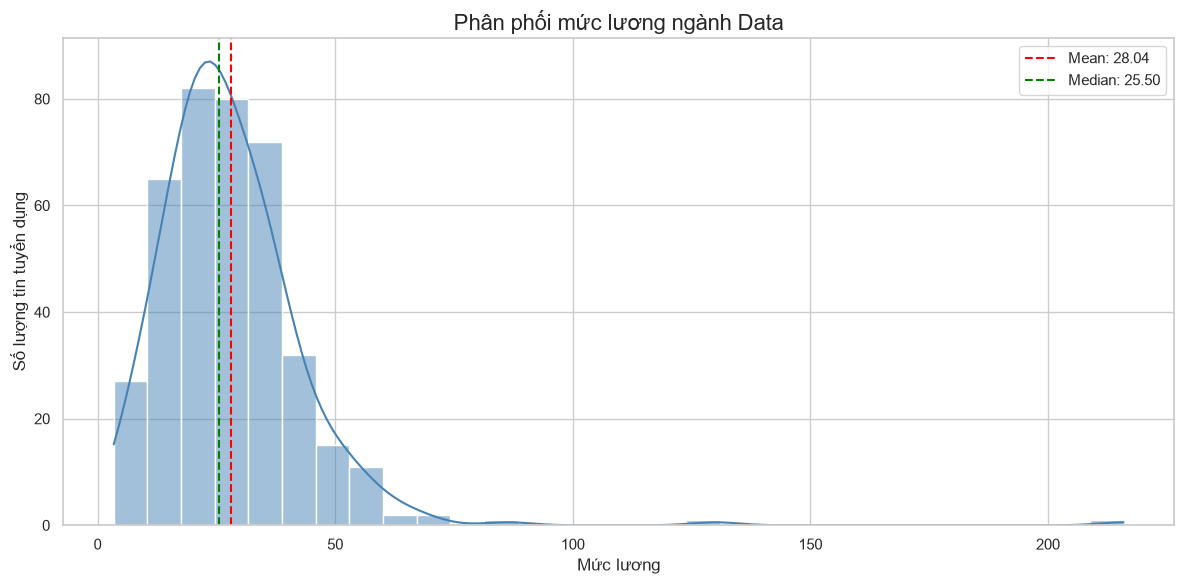

In [7]:
# Lọc các tin tuyển dụng có công bố mức lương
salary = df.loc[
    df["Trang_Thai_Luong"] == "Co_Cong_Bo",
    "Luong_Trung_Binh"
].dropna()

# Vẽ Histogram
plt.figure(figsize=(12, 6))

sns.histplot(
    salary,
    bins=30,
    kde=True,
    color="steelblue"
)

# Đường trung bình
plt.axvline(
    salary.mean(),
    color="red",
    linestyle="--",
    label=f"Mean: {salary.mean():.2f}"
)

# Đường trung vị
plt.axvline(
    salary.median(),
    color="green",
    linestyle="--",
    label=f"Median: {salary.median():.2f}"
)

plt.title("Phân phối mức lương ngành Data", fontsize=16)
plt.xlabel("Mức lương")
plt.ylabel("Số lượng tin tuyển dụng")
plt.legend()
plt.tight_layout()
plt.show()

#### Nhận xét

- Mức lương tập trung chủ yếu trong khoảng từ 15 đến 40.
- Phân phối mức lương có dạng lệch phải.
- Mức lương trung bình (28,04) cao hơn mức lương trung vị (25,50).
- Một số tin tuyển dụng có mức lương đặc biệt cao, với giá trị
  lớn nhất là 215,90.
- Các mức lương cao bất thường có thể kéo giá trị trung bình
  lên cao.
- Kết quả chỉ phản ánh 391 tin tuyển dụng có công bố mức lương,
  tương đương 25,27% tổng số tin tuyển dụng.

### 2.2.3. So sánh mức lương giữa 5 nhóm ngành Data

Sử dụng biểu đồ Boxplot để so sánh mức lương trung vị,
độ phân tán và các giá trị ngoại lệ giữa các nhóm ngành.

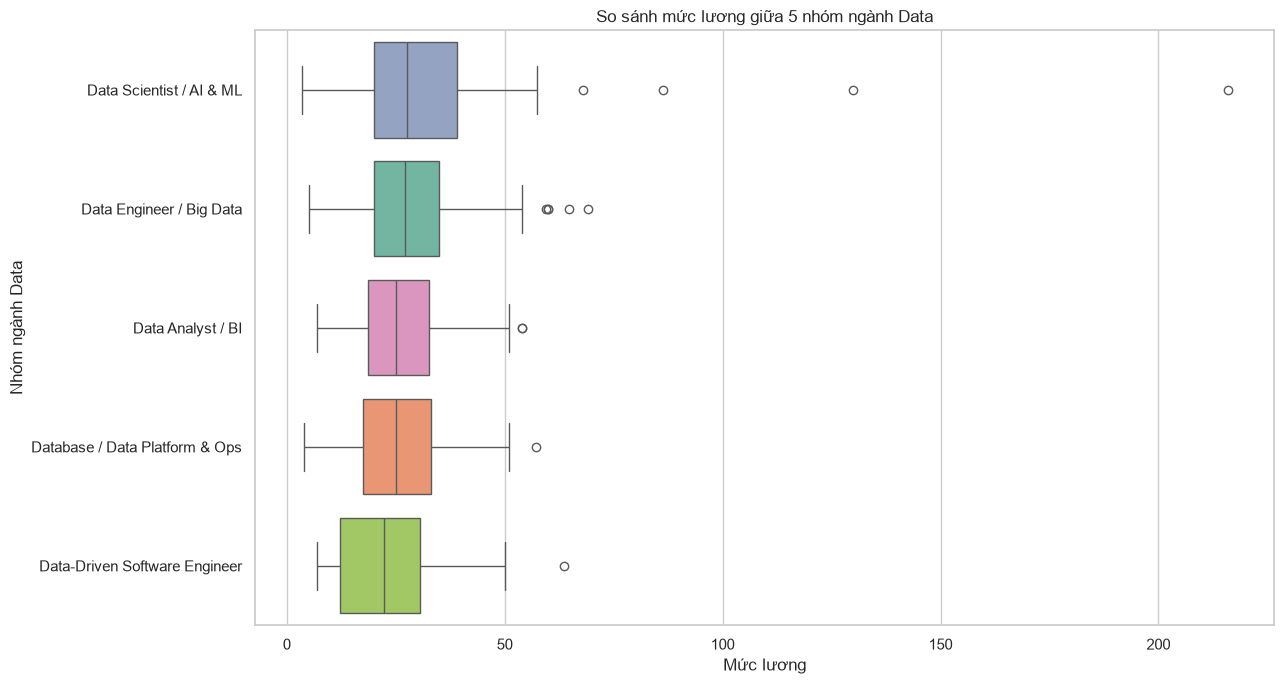

In [8]:
# Lọc dữ liệu có công bố mức lương
df_salary = df.loc[
    (df["Trang_Thai_Luong"] == "Co_Cong_Bo")
    & df["Luong_Trung_Binh"].notna()
].copy()

# Sắp xếp nhóm ngành theo mức lương trung vị
order = (
    df_salary.groupby("Nhom_Nganh_Data")["Luong_Trung_Binh"]
    .median()
    .sort_values(ascending=False)
    .index
)

# Vẽ Boxplot
plt.figure(figsize=(13, 7))

sns.boxplot(
    data=df_salary,
    x="Luong_Trung_Binh",
    y="Nhom_Nganh_Data",
    hue="Nhom_Nganh_Data",
    order=order,
    palette="Set2",
    legend=False
)

plt.title("So sánh mức lương giữa 5 nhóm ngành Data")
plt.xlabel("Mức lương")
plt.ylabel("Nhóm ngành Data")
plt.tight_layout()
plt.show()

### 2.2.5. Phân tích tương quan giữa các kỹ năng

Sử dụng Heatmap để khảo sát mối tương quan giữa
60 kỹ năng trong dữ liệu tuyển dụng, từ đó xác định
những kỹ năng có xu hướng xuất hiện cùng nhau.

In [9]:
# Lấy 60 cột kỹ năng
skill_cols = [
    col for col in df.columns
    if col.startswith("Skill_")
]

# Tạo ma trận tương quan Pearson
skill_corr = df[skill_cols].corr(method="pearson")

# Loại bỏ tiền tố Skill_ khi hiển thị
skill_corr.index = skill_corr.index.str.replace("Skill_", "")
skill_corr.columns = skill_corr.columns.str.replace("Skill_", "")

print("Kích thước ma trận:", skill_corr.shape)

skill_corr.head()

Kích thước ma trận: (60, 60)


,Python,SQL,R,Scala,Java,C_Cpp,JavaScript,Bash_Shell,PowerBI,Tableau,Looker,Excel,Statistics,AB_Testing,Data_Storytelling,Spark,Hadoop,Kafka,Airflow,dbt,ETL,Data_Warehouse,Data_Lake,Data_Modeling,Machine_Learning,Deep_Learning,Pandas,NumPy,Scikit_Learn,PyTorch,TensorFlow,NLP,Computer_Vision,LLM_GenAI,MLOps,PostgreSQL,MySQL,SQL_Server,Oracle,MongoDB,Redis,Elasticsearch,BigQuery,Snowflake,Databricks,Redshift,Cloud_AWS,Cloud_Azure,Cloud_GCP,Docker,Kubernetes,Git,Linux,CI_CD,English,Communication,Problem_Solving,Teamwork,Agile_Scrum,Data_Governance
Python,1.000000,0.066463,0.122858,0.078840,-0.102133,0.110548,-0.018580,0.184550,-0.004223,0.027841,0.019694,-0.034344,0.063147,0.038674,-0.003484,0.100931,0.040692,-0.109767,0.096134,0.079171,0.329313,0.011312,0.047270,-0.039341,0.181605,0.148354,0.114062,0.082507,0.090441,0.157691,0.154963,0.074759,0.103220,0.176637,0.099770,-0.151810,-0.155478,-0.214339,-0.235988,-0.091947,-0.116091,-0.023485,0.080690,-0.002227,0.015095,0.053441,0.019289,0.020295,0.034871,-0.002230,-0.034973,0.021431,-0.021550,-0.052918,-0.068704,-0.101122,-0.017065,-0.043497,-0.157871,-0.074920
SQL,0.066463,1.000000,0.050698,0.017379,0.132321,-0.085514,0.117199,-0.105570,0.053803,0.082160,0.051197,-0.053876,0.006299,-0.073226,-0.034179,0.037802,0.035645,0.066820,-0.032527,0.050698,0.212272,0.057858,0.036629,0.101327,-0.265101,-0.193528,0.043506,0.032415,-0.010389,-0.195039,-0.143576,-0.139935,-0.210377,-0.230119,-0.172150,0.335195,0.285938,0.254930,0.180341,0.227249,0.164203,-0.004673,0.077299,0.022977,-0.049937,0.049615,-0.092888,-0.063372,-0.039613,-0.000063,-0.040990,0.053655,0.003993,-0.018126,-0.071341,0.002439,0.025995,0.024164,0.064754,-0.066668
R,0.122858,0.050698,1.000000,0.036175,-0.057446,-0.021026,-0.058424,-0.031065,0.130038,0.087874,0.114308,0.087008,0.265979,-0.018005,0.105149,0.059822,0.101881,-0.017263,0.013590,-0.014426,-0.023219,0.092849,0.007891,-0.040509,0.097437,0.024765,-0.013393,-0.009688,-0.010620,-0.021951,0.013528,-0.022842,-0.026537,-0.053735,0.033774,-0.065787,-0.027122,-0.049034,0.036261,-0.052732,-0.042202,-0.031065,-0.018539,-0.015394,-0.012279,-0.012279,-0.031451,-0.047601,-0.024561,-0.036637,-0.024444,-0.024841,-0.044266,-0.049047,-0.008259,0.020467,-0.007789,0.029589,-0.047339,0.050260
Scala,0.078840,0.017379,0.036175,1.000000,0.127602,0.015032,-0.024401,-0.028841,-0.021121,0.007563,0.017484,-0.032482,-0.018228,-0.016716,0.058620,0.399595,0.324796,0.190988,0.091469,0.085744,0.084129,0.082084,0.239710,0.001153,-0.000145,-0.024816,-0.012435,-0.008995,-0.009859,-0.020379,-0.018628,-0.021207,-0.024637,-0.018400,0.008887,0.022502,-0.005615,-0.045524,-0.001123,0.094544,0.054647,0.092205,0.177431,0.078799,-0.011400,0.104621,0.063797,0.075749,0.111462,-0.015879,0.028832,-0.045516,-0.041097,-0.002411,0.028663,0.034332,-0.013802,0.009354,-0.009542,0.107009
Java,-0.102133,0.132321,-0.057446,0.127602,1.000000,0.121592,0.235981,-0.062051,-0.154495,-0.088370,-0.079899,-0.133136,-0.122921,-0.037716,-0.159570,0.031093,0.041126,0.288363,-0.008483,-0.015368,-0.194465,-0.088760,-0.033915,0.019664,-0.121046,-0.051614,-0.038255,-0.038579,-0.042288,-0.068628,-0.049243,-0.054768,-0.050486,-0.044688,-0.068169,0.285918,0.274009,0.132206,0.254724,0.227653,0.230195,0.116057,0.014298,0.004555,-0.048894,0.000350,0.100530,0.052873,0.061424,0.236406,0.218155,0.187536,0.048924,0.206706,0.051884,0.085679,0.041128,0.098109,0.137657,-0.099265


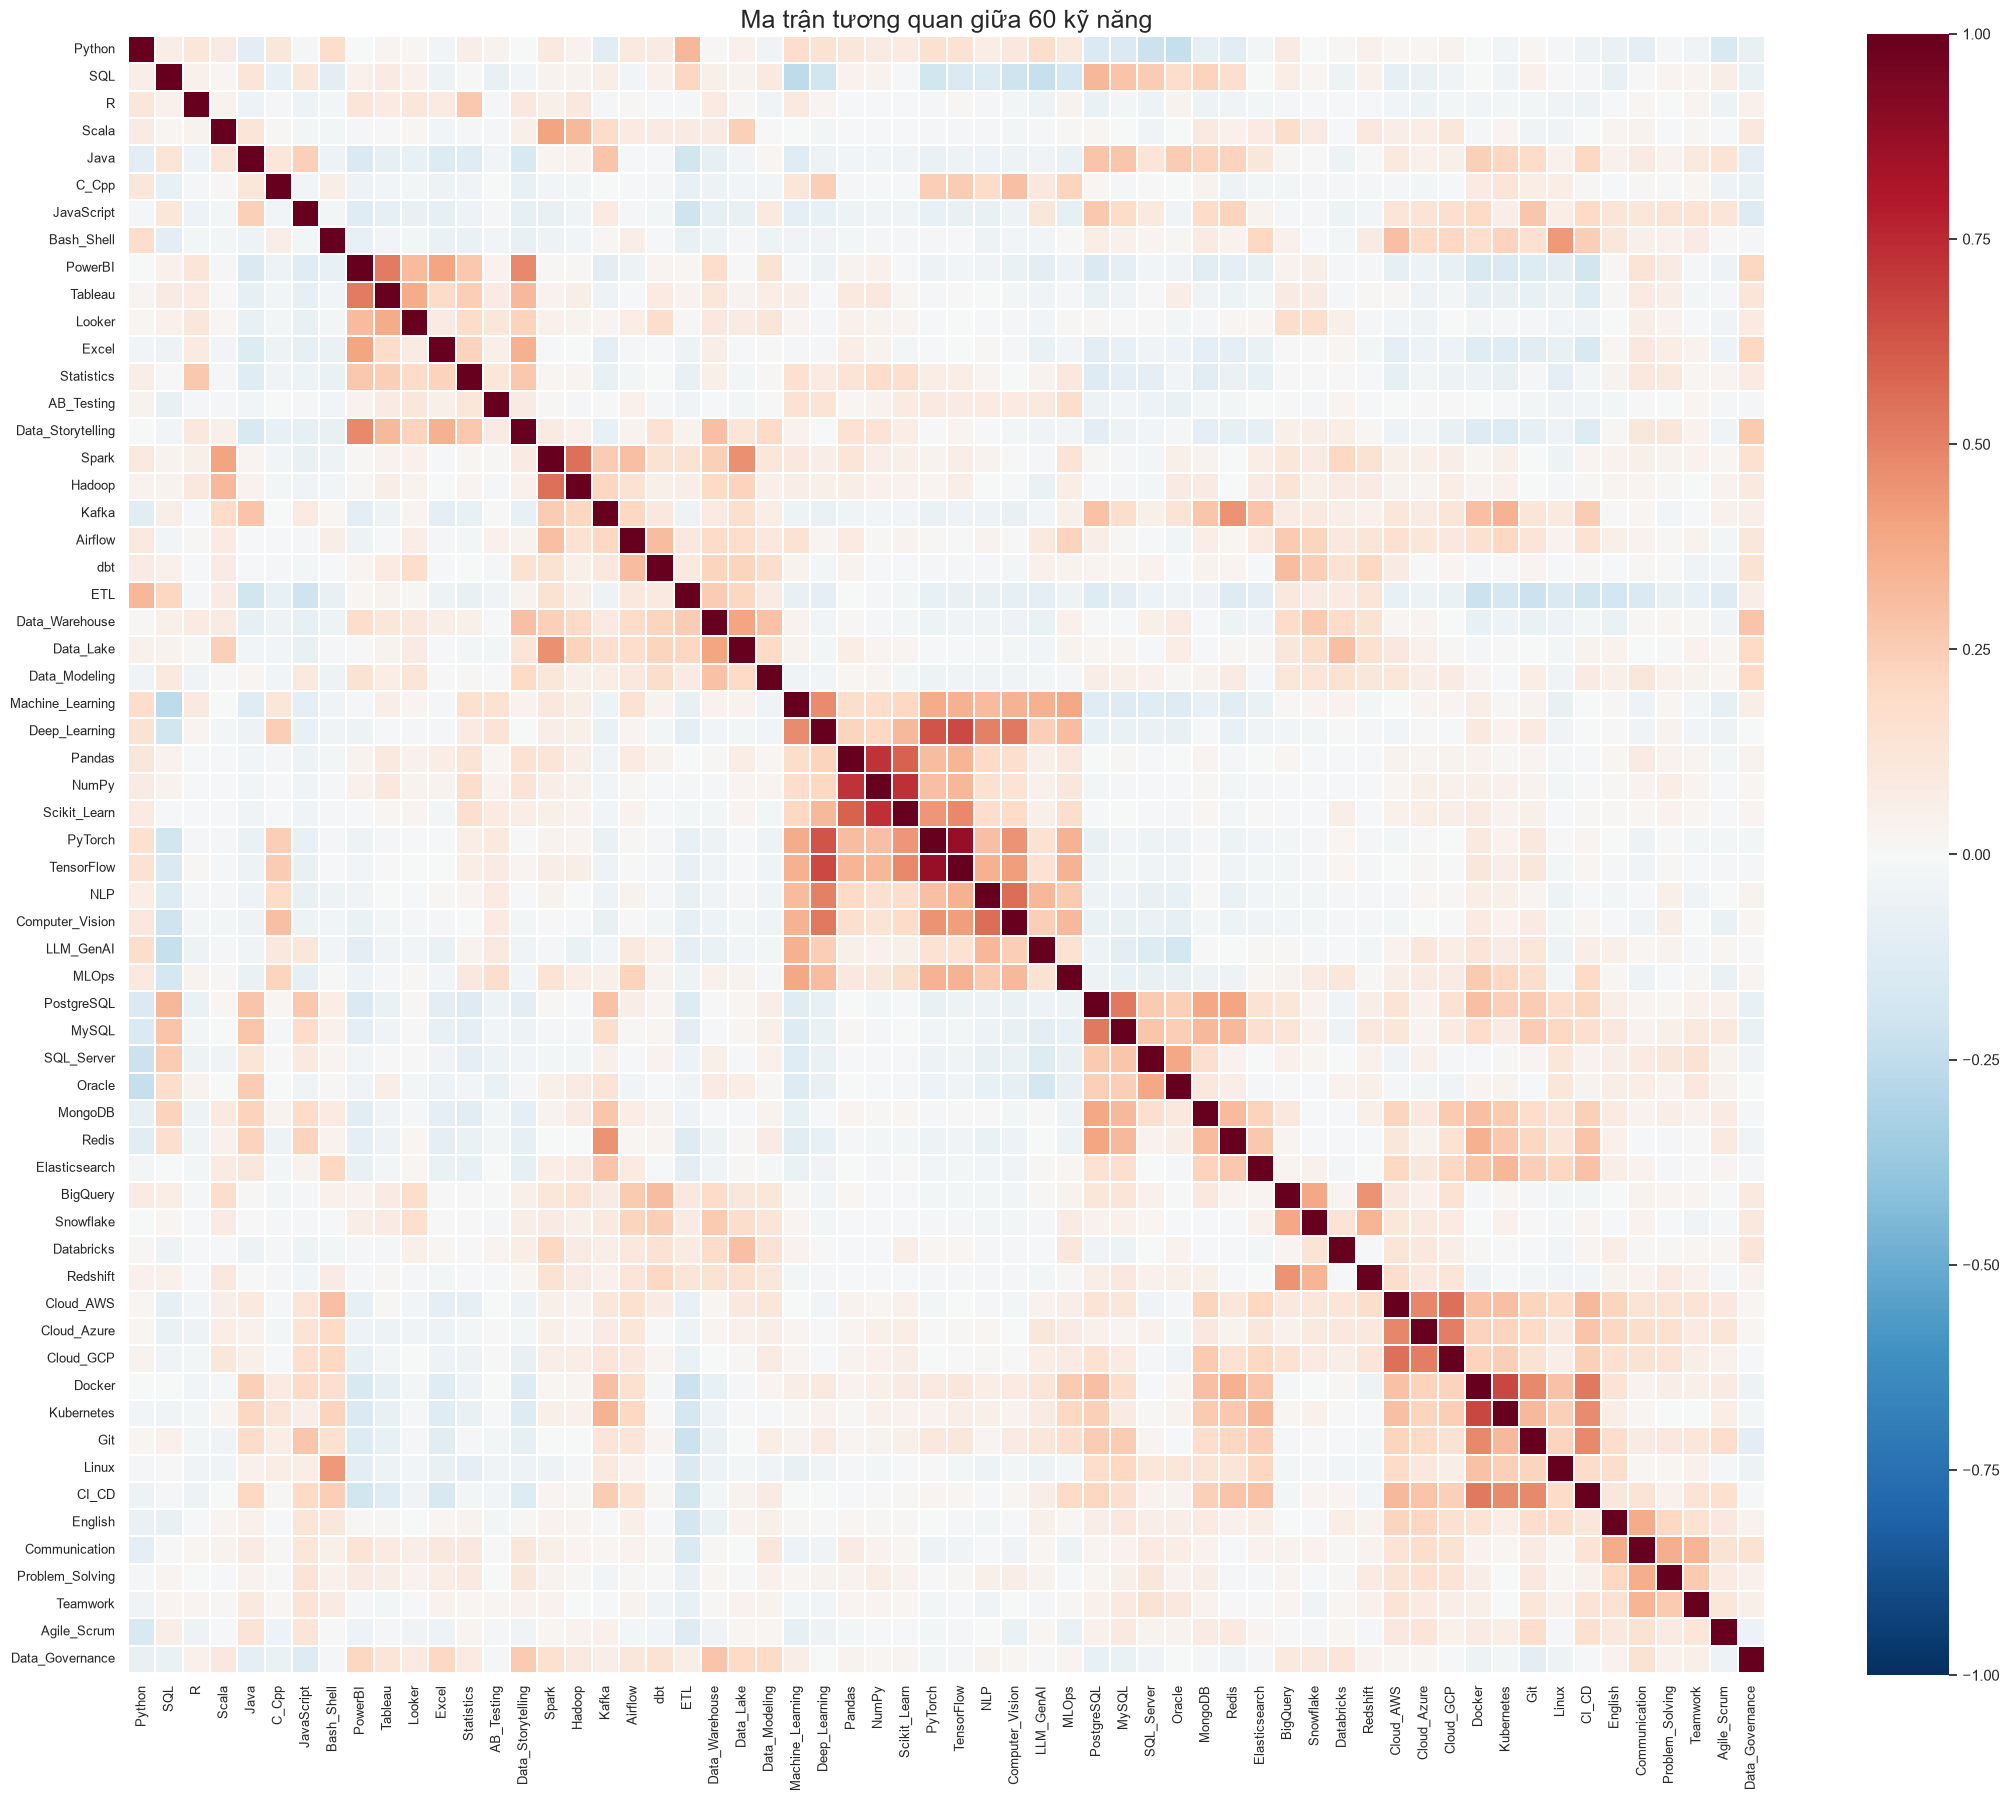

In [10]:
plt.figure(figsize=(22, 18))

sns.heatmap(
    skill_corr,
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    annot=False,
    linewidths=0.1
)

plt.title(
    "Ma trận tương quan giữa 60 kỹ năng",
    fontsize=18
)

plt.xticks(rotation=90, fontsize=9)
plt.yticks(rotation=0, fontsize=9)

plt.tight_layout()
plt.show()

In [11]:
#### Top 10 cặp kỹ năng có tương quan dương cao nhất

In [12]:
# Chỉ lấy nửa trên của ma trận, loại bỏ đường chéo
mask = np.triu(
    np.ones(skill_corr.shape, dtype=bool),
    k=1
)

# Trích xuất các cặp kỹ năng có tương quan dương
pairs = skill_corr.where(mask).stack()

top_corr = (
    pairs[pairs > 0]
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

top_corr.columns = [
    "Ky_Nang_1",
    "Ky_Nang_2",
    "He_So_Tuong_Quan"
]

top_corr.round(4)

,Ky_Nang_1,Ky_Nang_2,He_So_Tuong_Quan
0,PyTorch,TensorFlow,0.8691
1,NumPy,Scikit_Learn,0.7284
2,Pandas,NumPy,0.7233
3,Docker,Kubernetes,0.6657
4,Deep_Learning,TensorFlow,0.6569
5,Deep_Learning,PyTorch,0.6316
6,Pandas,Scikit_Learn,0.5922
7,NLP,Computer_Vision,0.5599
8,Cloud_AWS,Cloud_GCP,0.5502
9,Spark,Hadoop,0.5496


### 2.2.7. Phân tích phân bố địa lý

Khảo sát nhu cầu tuyển dụng ngành Data theo địa điểm,
xác định những khu vực tập trung nhiều tin tuyển dụng nhất.

In [13]:
location_counts = df["Dia_Diem_Chuan"].value_counts()

location_counts

Dia_Diem_Chuan
Hà Nội     869
TP.HCM     561
Khác        92
Đà Nẵng     21
Remote       4
Name: count, dtype: int64

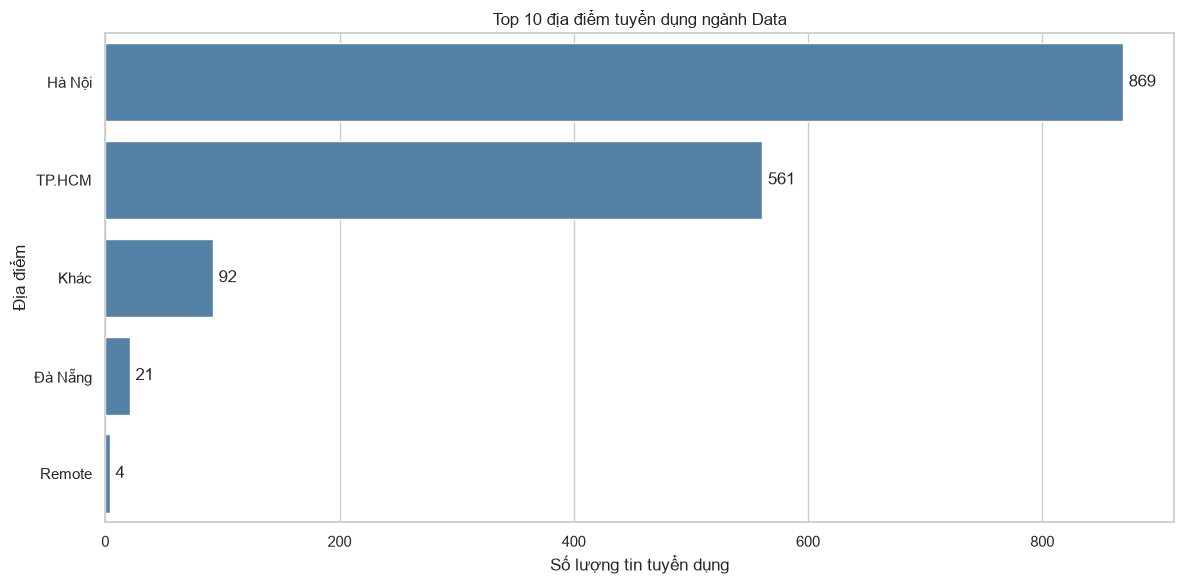

In [14]:
top_locations = location_counts.head(10)

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    x=top_locations.values,
    y=top_locations.index,
    color="steelblue"
)

ax.bar_label(ax.containers[0], padding=4)

plt.title("Top 10 địa điểm tuyển dụng ngành Data")
plt.xlabel("Số lượng tin tuyển dụng")
plt.ylabel("Địa điểm")
plt.tight_layout()
plt.show()

### 2.2.8. Phân tích mô hình làm việc

Khảo sát tỷ lệ các mô hình làm việc trong ngành Data,
bao gồm Onsite, Hybrid và Remote. Qua đó xác định
xu hướng tổ chức công việc của các doanh nghiệp.

In [15]:
work_counts = df["Mo_Hinh_Lam_Viec"].value_counts()

work_summary = pd.DataFrame({
    "So_Luong": work_counts,
    "Ty_Le (%)": (work_counts / len(df) * 100).round(2)
})

work_summary

,So_Luong,Ty_Le (%)
Mo_Hinh_Lam_Viec,,
On-site,1401,90.56
Hybrid,102,6.59
Remote,44,2.84


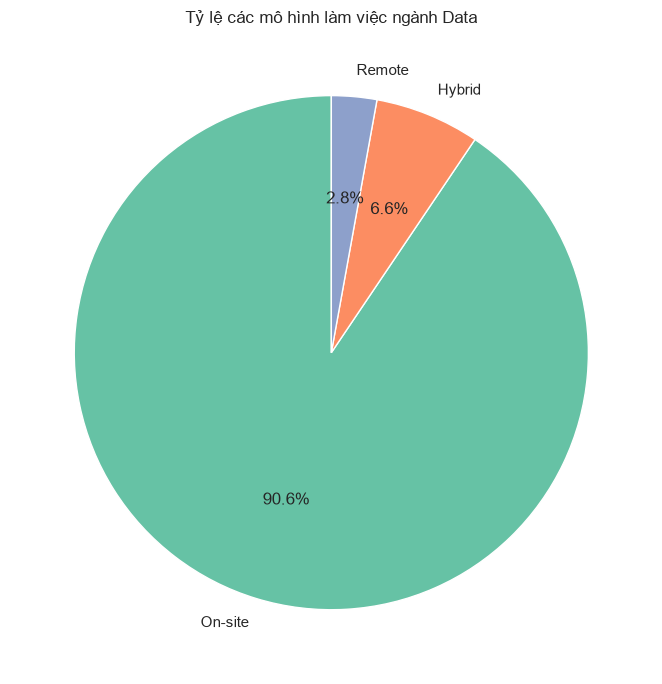

In [16]:
plt.figure(figsize=(9, 7))

plt.pie(
    work_counts.values,
    labels=work_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=sns.color_palette("Set2", len(work_counts)),
    wedgeprops={"edgecolor": "white"}
)

plt.title("Tỷ lệ các mô hình làm việc ngành Data")
plt.tight_layout()
plt.show()

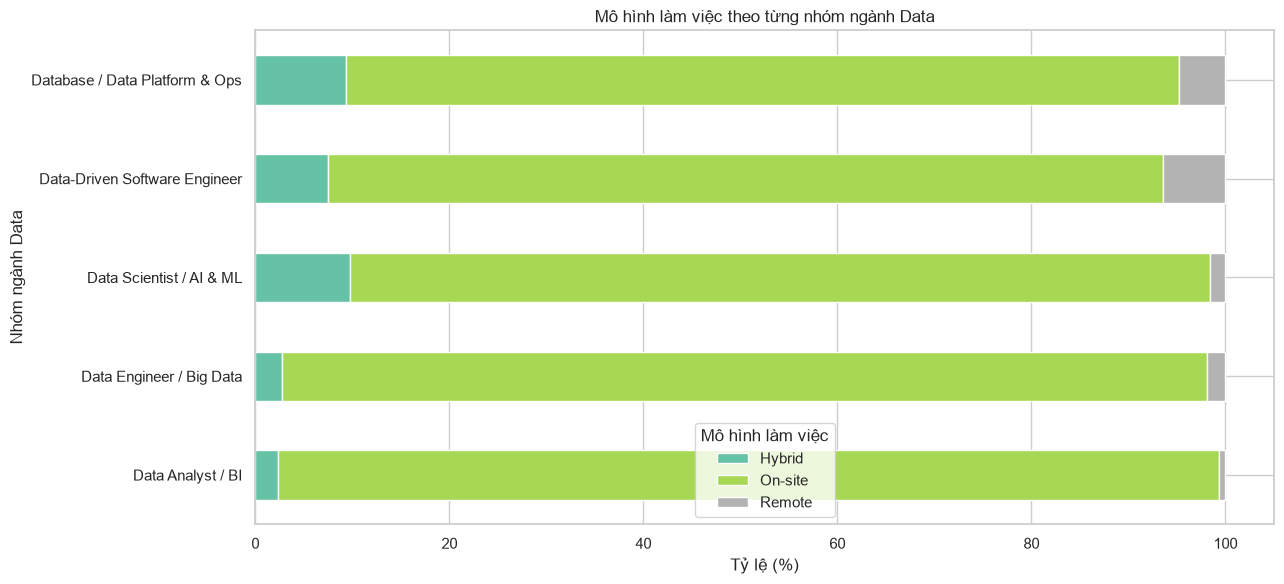

In [17]:
work_by_field = pd.crosstab(
    df["Nhom_Nganh_Data"],
    df["Mo_Hinh_Lam_Viec"],
    normalize="index"
) * 100

work_by_field.plot(
    kind="barh",
    stacked=True,
    figsize=(13, 6),
    colormap="Set2"
)

plt.title("Mô hình làm việc theo từng nhóm ngành Data")
plt.xlabel("Tỷ lệ (%)")
plt.ylabel("Nhóm ngành Data")
plt.legend(title="Mô hình làm việc")
plt.tight_layout()
plt.show()

## 2.3. Phân cụm nghề nghiệp bằng K-Means

### 2.3.1. Chuẩn bị và chuẩn hóa dữ liệu

Sử dụng các thuộc tính kỹ năng để phân cụm các tin
tuyển dụng có đặc điểm nghề nghiệp tương đồng.

In [18]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

In [19]:
skill_cols = [
    col for col in df.columns
    if col.startswith("Skill_")
]

X = df[skill_cols].copy()

print("Kích thước dữ liệu phân cụm:", X.shape)
print("Số giá trị thiếu:", X.isna().sum().sum())
print("Số tin không ghi nhận kỹ năng:", (X.sum(axis=1) == 0).sum())

X.head()

Kích thước dữ liệu phân cụm: (1547, 60)
Số giá trị thiếu: 0
Số tin không ghi nhận kỹ năng: 0


,Skill_Python,Skill_SQL,Skill_R,Skill_Scala,Skill_Java,Skill_C_Cpp,Skill_JavaScript,Skill_Bash_Shell,Skill_PowerBI,Skill_Tableau,Skill_Looker,Skill_Excel,Skill_Statistics,Skill_AB_Testing,Skill_Data_Storytelling,Skill_Spark,Skill_Hadoop,Skill_Kafka,Skill_Airflow,Skill_dbt,Skill_ETL,Skill_Data_Warehouse,Skill_Data_Lake,Skill_Data_Modeling,Skill_Machine_Learning,Skill_Deep_Learning,Skill_Pandas,Skill_NumPy,Skill_Scikit_Learn,Skill_PyTorch,Skill_TensorFlow,Skill_NLP,Skill_Computer_Vision,Skill_LLM_GenAI,Skill_MLOps,Skill_PostgreSQL,Skill_MySQL,Skill_SQL_Server,Skill_Oracle,Skill_MongoDB,Skill_Redis,Skill_Elasticsearch,Skill_BigQuery,Skill_Snowflake,Skill_Databricks,Skill_Redshift,Skill_Cloud_AWS,Skill_Cloud_Azure,Skill_Cloud_GCP,Skill_Docker,Skill_Kubernetes,Skill_Git,Skill_Linux,Skill_CI_CD,Skill_English,Skill_Communication,Skill_Problem_Solving,Skill_Teamwork,Skill_Agile_Scrum,Skill_Data_Governance
0,1,1,0,1,0,0,0,0,1,1,1,0,0,0,1,1,1,1,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,1,1,1,1,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0
1,1,1,0,0,0,0,0,0,0,0,1,0,0,0,1,1,0,1,1,1,1,1,1,1,0,0,0,0,0,0,0,0,0,1,1,1,0,1,0,1,1,0,0,0,1,0,1,0,0,1,1,0,0,1,1,0,0,0,0,1
2,1,1,0,1,1,0,0,0,0,0,0,0,1,0,1,1,1,1,0,1,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,1,1,0,1,1,0,1,1,1,1,0,0,0,0,0,0,0,0,0,0,1
3,1,1,0,0,0,0,0,1,1,1,1,0,0,0,1,0,0,1,1,1,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,1,1,1,0,1,1,1,1,1,0,0,0,0,0,1,1,1,1,0,0,1,0,0,0,1
4,1,1,0,0,0,0,0,0,0,0,0,0,0,0,1,1,1,1,1,1,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,1,0,1,1,1,0,0,0,0,1,1,1,1,1,1,1


### 2.3.2. Chuẩn hóa dữ liệu bằng StandardScaler

Chuẩn hóa các thuộc tính trước khi thực hiện K-Means
nhằm điều chỉnh ảnh hưởng của các đặc trưng khi tính
khoảng cách Euclid.

In [20]:
# Chuẩn hóa dữ liệu
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Kích thước dữ liệu:", X_scaled.shape)

print("Dữ liệu sau chuẩn hóa:")
print(X_scaled[:5])

Kích thước dữ liệu: (1547, 60)
Dữ liệu sau chuẩn hóa:
[[ 1.02288626  0.62444944 -0.12010924  8.96777858 -0.47828128 -0.17506066
  -0.48642647 -0.25864368  2.8090576   4.9356515   5.986095   -0.29129493
  -0.33726977 -0.14990634  2.2045064   4.9356515   7.11102431  2.46907478
  -0.26006317 -0.12010924  1.90571155 -0.27937212  5.36190265 -0.33726977
  -0.43378802 -0.22254236 -0.11151034 -0.0806609  -0.08841713 -0.18275703
  -0.16705381 -0.19018093 -0.22093791 -0.44738703 -0.19736341  1.82574186
   2.1554548  -0.40824829  2.27771816  2.27771816  2.84604989  3.86632301
   6.47859724 -0.128163   -0.1022286  -0.1022286  -0.4915008  -0.39631813
   2.85549403 -0.52574009 -0.44738703 -0.5347446  -0.36855076 -0.61246315
  -0.73541597 -0.70026144 -0.51269596 -0.46599555  2.53722289 -0.49555187]
 [ 1.02288626  0.62444944 -0.12010924 -0.11151034 -0.47828128 -0.17506066
  -0.48642647 -0.25864368 -0.35599128 -0.2026075   5.986095   -0.29129493
  -0.33726977 -0.14990634  2.2045064   4.9356515  -0.1406

### 2.3.3. Xác định số cụm bằng Elbow Method

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

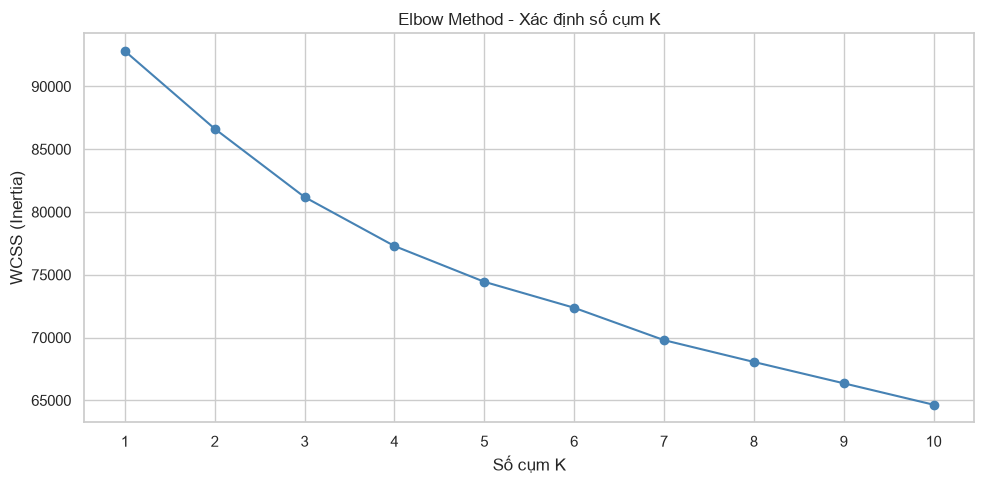

In [22]:
inertias = []
K_range = range(1, 11)

for k in K_range:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)

    inertias.append(kmeans.inertia_)

plt.figure(figsize=(10, 5))

plt.plot(
    K_range,
    inertias,
    marker="o",
    color="steelblue"
)

plt.title("Elbow Method - Xác định số cụm K")
plt.xlabel("Số cụm K")
plt.ylabel("WCSS (Inertia)")
plt.xticks(list(K_range))
plt.grid(True)
plt.tight_layout()
plt.show()

In [23]:
print("Kích thước:", X_scaled.shape)
print("Số giá trị NaN:", np.isnan(X_scaled).sum())
print("Số giá trị vô cực:", np.isinf(X_scaled).sum())
print("WCSS tại K = 1:", inertias[0])
print("Số đặc trưng có biến thiên:", (X.std(ddof=0) > 0).sum())

Kích thước: (1547, 60)
Số giá trị NaN: 0
Số giá trị vô cực: 0
WCSS tại K = 1: 92820.00000000001
Số đặc trưng có biến thiên: 60


### 2.3.4. Đánh giá chất lượng phân cụm bằng Silhouette Score

K = 2: Silhouette Score = 0.1390
K = 3: Silhouette Score = 0.1471


K = 4: Silhouette Score = 0.1397


K = 5: Silhouette Score = 0.1309


K = 6: Silhouette Score = 0.1070


K = 7: Silhouette Score = 0.0819


K = 8: Silhouette Score = 0.0852
K = 9: Silhouette Score = 0.0843


K = 10: Silhouette Score = 0.0556


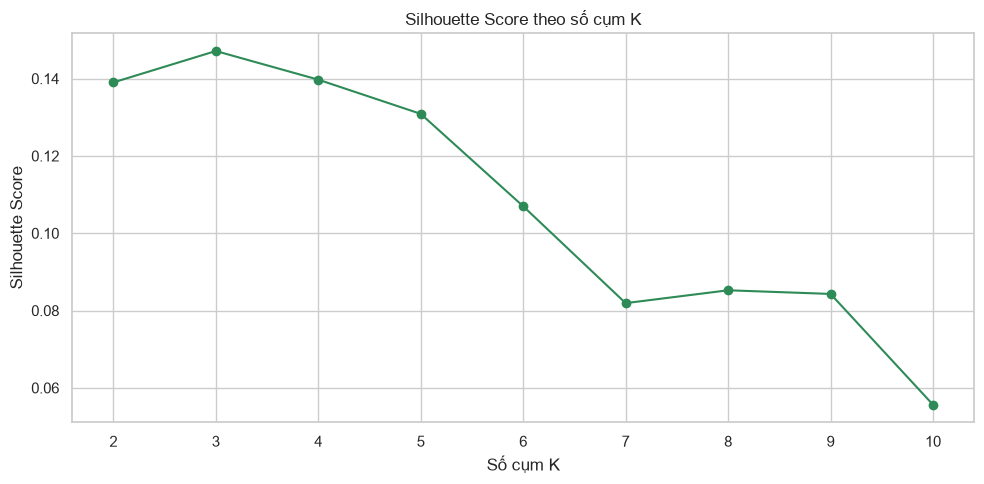

In [24]:
silhouette_scores = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)

    silhouette_scores.append(score)

    print(f"K = {k}: Silhouette Score = {score:.4f}")

plt.figure(figsize=(10, 5))

plt.plot(
    range(2, 11),
    silhouette_scores,
    marker="o",
    color="seagreen"
)

plt.title("Silhouette Score theo số cụm K")
plt.xlabel("Số cụm K")
plt.ylabel("Silhouette Score")
plt.xticks(range(2, 11))
plt.grid(True)
plt.tight_layout()
plt.show()

In [25]:
evaluation = pd.DataFrame({
    "K": range(2, 11),
    "WCSS": inertias[1:],
    "Silhouette_Score": silhouette_scores
})

display(evaluation.round(4))

best_k = evaluation.loc[
    evaluation["Silhouette_Score"].idxmax(), "K"
]

print("K có Silhouette Score cao nhất:", best_k)

,K,WCSS,Silhouette_Score
0,2,86631.3187,0.1390
1,3,81190.6098,0.1471
2,4,77291.1810,0.1397
3,5,74442.5174,0.1309
4,6,72372.8247,0.1070
5,7,69796.1171,0.0819
6,8,68058.3763,0.0852
7,9,66359.5759,0.0843
8,10,64652.2257,0.0556


K có Silhouette Score cao nhất: 3


### 2.3.6. Huấn luyện mô hình K-Means

Thực hiện phân cụm với K = 3 để khám phá ba nhóm
chân dung nghề nghiệp dựa trên đặc điểm kỹ năng.

In [26]:
k_final = 3

kmeans_final = KMeans(
    n_clusters=k_final,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans_final.fit_predict(X_scaled)

# Tạo bản sao để giữ nguyên dữ liệu của Thành viên 1
df_cluster = df.copy()

df_cluster["Cluster"] = cluster_labels

print("WCSS:", kmeans_final.inertia_)
print("Silhouette Score:", silhouette_score(
    X_scaled, cluster_labels
))

WCSS: 81190.60977444211


Silhouette Score: 0.14712845663409307


In [27]:
cluster_counts = df_cluster["Cluster"].value_counts().sort_index()

cluster_summary = pd.DataFrame({
    "So_Luong": cluster_counts,
    "Ty_Le (%)": (cluster_counts / len(df_cluster) * 100).round(2)
})

cluster_summary

,So_Luong,Ty_Le (%)
Cluster,,
0,59,3.81
1,994,64.25
2,494,31.93


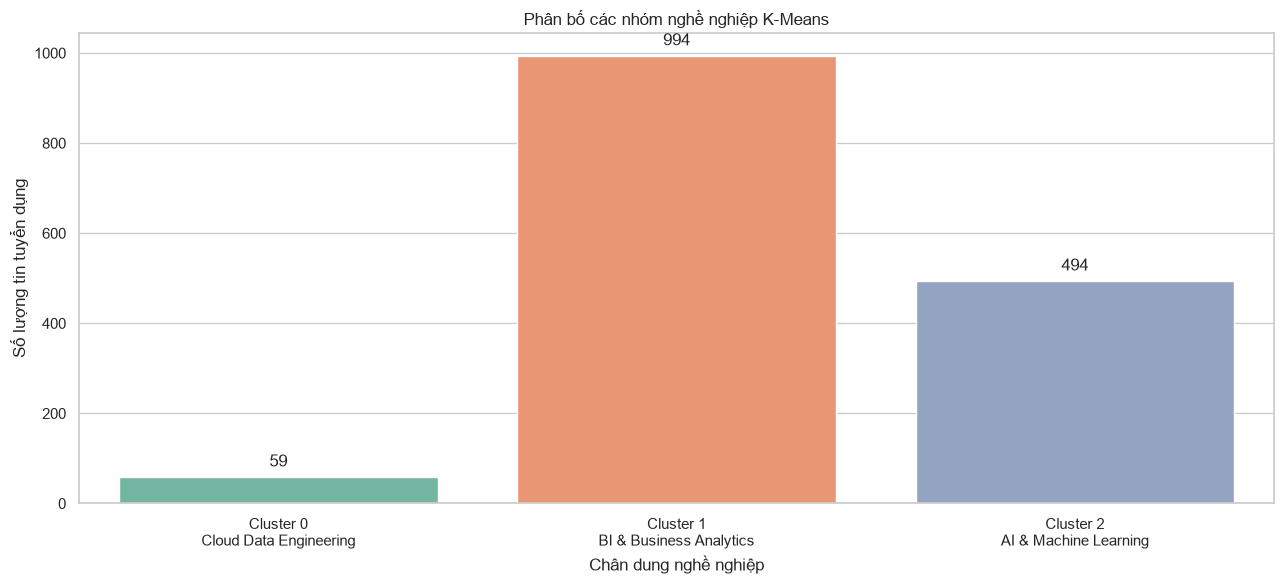

In [28]:
# Tên cụm minh họa, cần đối chiếu với cluster_profiles
cluster_names = {
    0: "Cloud Data Engineering",
    1: "BI & Business Analytics",
    2: "AI & Machine Learning"
}

df_cluster["Cluster_Name"] = df_cluster["Cluster"].map(cluster_names)

plt.figure(figsize=(13, 6))

ax = sns.countplot(
    data=df_cluster,
    x="Cluster",
    hue="Cluster",
    palette="Set2",
    order=[0, 1, 2],
    legend=False
)

# Hiển thị số lượng trên mỗi cột
for container in ax.containers:
    ax.bar_label(container, padding=5)

# Thêm chú thích cho từng cụm
ax.set_xticks([0, 1, 2])

ax.set_xticklabels([
    f"Cluster {i}\n{cluster_names[i]}"
    for i in range(3)
])

plt.title("Phân bố các nhóm nghề nghiệp K-Means")
plt.xlabel("Chân dung nghề nghiệp")
plt.ylabel("Số lượng tin tuyển dụng")
plt.tight_layout()
plt.show()

### 2.3.7. Trực quan hóa kết quả phân cụm bằng PCA

Sử dụng PCA để giảm số chiều dữ liệu từ 60 xuống 2,
qua đó quan sát sự phân bố và mức độ tách biệt
giữa ba cụm nghề nghiệp.

In [29]:
# Giảm dữ liệu xuống 2 chiều
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

# Lưu tọa độ PCA
df_cluster["PCA1"] = X_pca[:, 0]
df_cluster["PCA2"] = X_pca[:, 1]

# Kiểm tra tỷ lệ phương sai được giữ lại
print(
    "Tỷ lệ phương sai giữ lại:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

Tỷ lệ phương sai giữ lại: 17.19 %


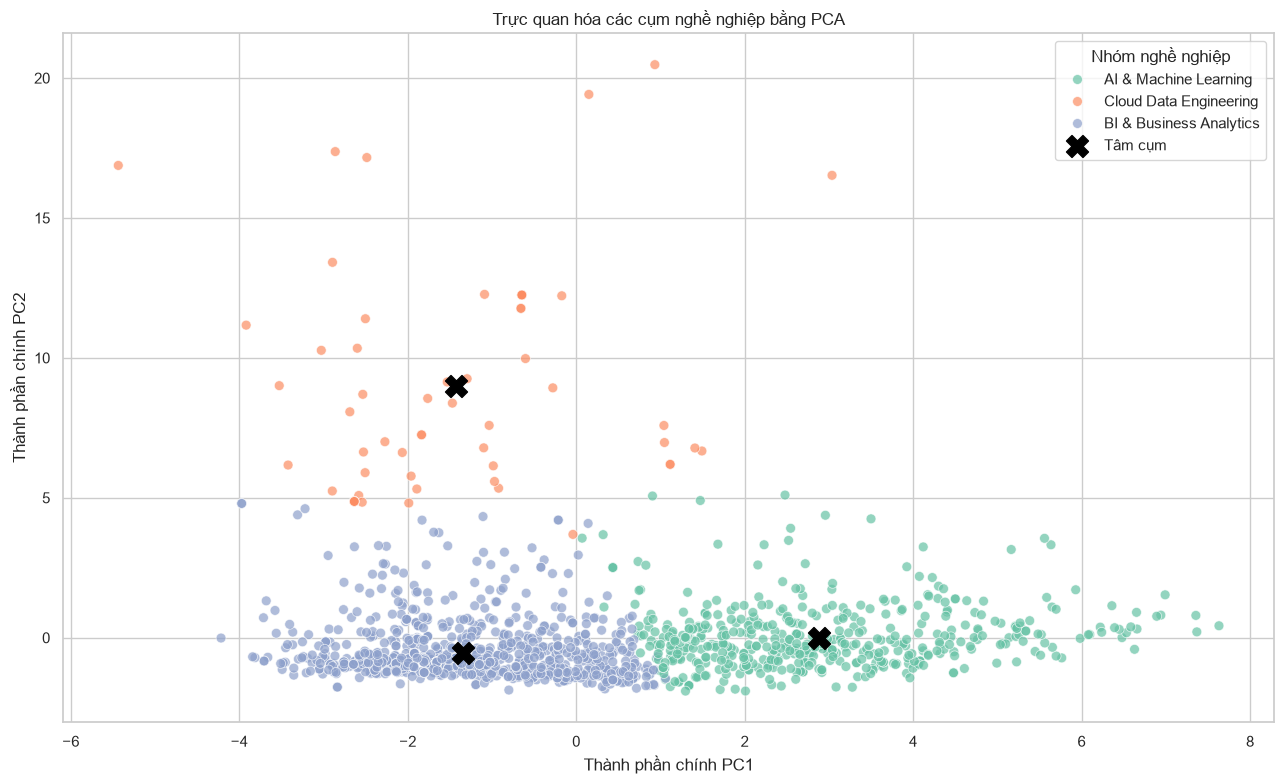

In [30]:
plt.figure(figsize=(13, 8))

sns.scatterplot(
    data=df_cluster,
    x="PCA1",
    y="PCA2",
    hue="Cluster_Name",
    palette="Set2",
    alpha=0.7,
    s=50
)

# Chiếu tâm cụm xuống không gian PCA
centers_pca = pca.transform(
    kmeans_final.cluster_centers_
)

plt.scatter(
    centers_pca[:, 0],
    centers_pca[:, 1],
    c="black",
    marker="X",
    s=250,
    label="Tâm cụm"
)

plt.title("Trực quan hóa các cụm nghề nghiệp bằng PCA")
plt.xlabel("Thành phần chính PC1")
plt.ylabel("Thành phần chính PC2")
plt.legend(title="Nhóm nghề nghiệp")
plt.tight_layout()
plt.show()

Dấu X màu đen biểu diễn tâm cụm (Centroid) sau khi chiếu xuống không gian PCA.
#### Nhận xét kết quả phân cụm PCA

- K-Means với K = 3 đã phân chia dữ liệu tuyển dụng
  thành ba cụm có sự khác biệt về vị trí trong không gian PCA.
- Cụm màu cam phân tách chủ yếu theo thành phần PC2
  và có độ phân tán tương đối lớn.
- Hai cụm xanh lá và xanh tím phân tách chủ yếu theo
  thành phần PC1, tuy nhiên vẫn tồn tại sự chồng lấn.
- Sự chồng lấn có thể liên quan đến các kỹ năng chung
  giữa những nhóm nghề nghiệp.
- Kết quả PCA cần được kết hợp với Silhouette Score
  và đặc trưng kỹ năng để đánh giá chất lượng phân cụm.

### 2.3.8. Phân tích chân dung nghề nghiệp

Phân tích tỷ lệ xuất hiện của các kỹ năng trong từng cụm
để xác định đặc điểm nổi bật và đặt tên nhóm nghề nghiệp
dựa trên kết quả phân cụm thực tế.

In [31]:
cluster_profiles = (
    df_cluster.groupby("Cluster")[skill_cols]
    .mean() * 100
)

cluster_profiles.columns = (
    cluster_profiles.columns.str.replace("Skill_", "")
)

cluster_profiles.round(2)

,Python,SQL,R,Scala,Java,C_Cpp,JavaScript,Bash_Shell,PowerBI,Tableau,Looker,Excel,Statistics,AB_Testing,Data_Storytelling,Spark,Hadoop,Kafka,Airflow,dbt,ETL,Data_Warehouse,Data_Lake,Data_Modeling,Machine_Learning,Deep_Learning,Pandas,NumPy,Scikit_Learn,PyTorch,TensorFlow,NLP,Computer_Vision,LLM_GenAI,MLOps,PostgreSQL,MySQL,SQL_Server,Oracle,MongoDB,Redis,Elasticsearch,BigQuery,Snowflake,Databricks,Redshift,Cloud_AWS,Cloud_Azure,Cloud_GCP,Docker,Kubernetes,Git,Linux,CI_CD,English,Communication,Problem_Solving,Teamwork,Agile_Scrum,Data_Governance
Cluster,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
0,84.75,30.51,0.00,0.00,10.17,27.12,3.39,3.39,1.69,1.69,1.69,5.08,18.64,13.56,16.95,6.78,3.39,1.69,6.78,0.00,1.69,0.00,1.69,1.69,94.92,89.83,18.64,13.56,20.34,72.88,67.8,54.24,69.49,59.32,37.29,11.86,8.47,3.39,3.39,16.95,1.69,1.69,0.00,0.00,1.69,0.00,15.25,15.25,11.86,45.76,28.81,45.76,6.78,28.81,28.81,16.95,32.20,13.56,6.78,18.64
1,51.31,70.32,2.01,0.60,7.85,1.41,10.06,1.51,16.50,5.63,3.22,11.17,12.88,2.01,21.83,2.41,0.80,4.02,2.92,1.51,28.77,8.65,3.12,8.05,14.79,1.81,0.70,0.20,0.00,0.70,0.2,2.21,2.41,14.08,1.31,8.45,7.24,11.37,13.08,3.42,0.91,0.30,1.61,1.51,0.91,0.60,7.34,5.33,1.71,1.91,0.70,5.94,5.03,8.55,27.67,28.77,16.30,13.58,9.05,21.73
2,39.68,80.16,0.40,2.63,41.30,3.24,39.27,16.19,1.82,0.81,1.82,1.42,3.85,1.21,7.49,6.68,4.05,35.83,13.16,1.42,9.51,5.26,4.05,15.59,8.50,0.40,0.20,0.00,0.00,0.00,0.0,0.00,1.42,16.80,4.66,53.85,39.88,21.46,23.89,41.70,32.39,18.83,4.05,2.02,1.21,2.02,44.33,29.96,29.35,58.50,47.37,52.23,26.52,64.78,50.81,43.12,28.54,26.92,23.08,15.79


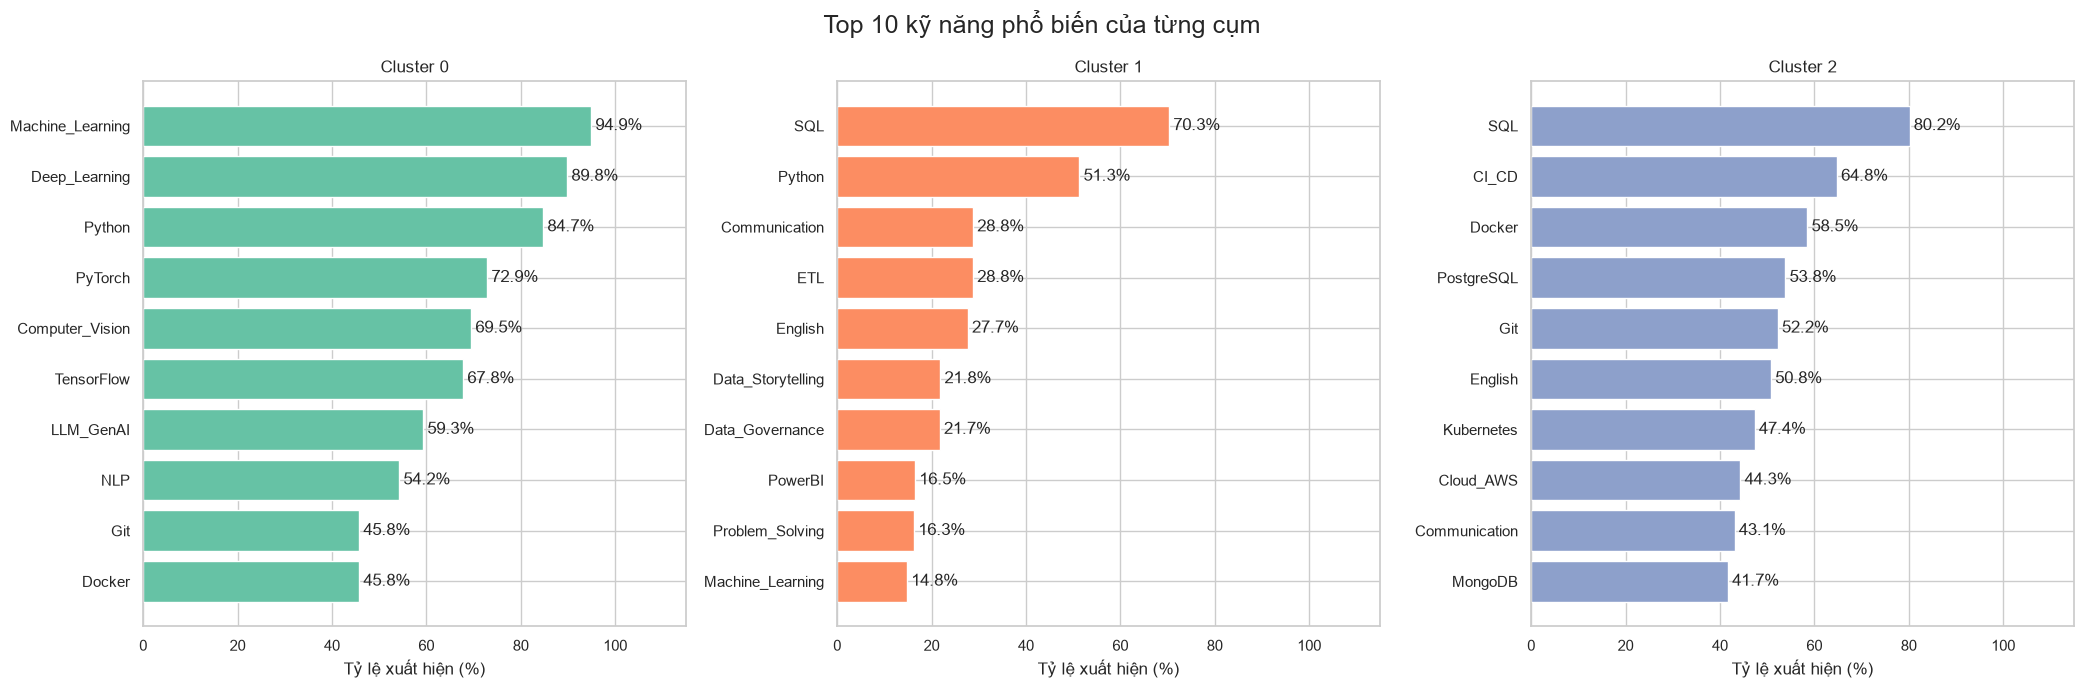

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(21, 7))

colors = sns.color_palette("Set2", 3)

for i, ax in enumerate(axes):

    top_skills = (
        cluster_profiles.loc[i]
        .sort_values(ascending=False)
        .head(10)
        .sort_values()
    )

    bars = ax.barh(
        top_skills.index,
        top_skills.values,
        color=colors[i]
    )

    ax.bar_label(bars, fmt="%.1f%%", padding=3)

    ax.set_title(f"Cluster {i}")
    ax.set_xlabel("Tỷ lệ xuất hiện (%)")
    ax.set_xlim(0, 115)

plt.suptitle(
    "Top 10 kỹ năng phổ biến của từng cụm",
    fontsize=18
)

plt.tight_layout()
plt.show()

## 2.4. Khai phá luật kết hợp (Association Rules)

### 2.4.1. Chuẩn bị dữ liệu

Sử dụng thuật toán Apriori để khai phá các tập kỹ năng
phổ biến và luật kết hợp giữa các kỹ năng tuyển dụng.
Đánh giá các luật bằng Support, Confidence và Lift.

In [33]:
from mlxtend.frequent_patterns import (
    apriori,
    fpgrowth,
    association_rules
)

In [34]:
# Lấy các cột kỹ năng
transactions = df[skill_cols].copy()

# Chuyển dữ liệu 0/1 thành False/True
transactions = transactions.astype(bool)

# Loại bỏ tiền tố Skill_
transactions.columns = (
    transactions.columns.str.replace("Skill_", "")
)

print("Số giao dịch:", len(transactions))
print("Số kỹ năng:", len(transactions.columns))

transactions.head()

Số giao dịch: 1547
Số kỹ năng: 60


,Python,SQL,R,Scala,Java,C_Cpp,JavaScript,Bash_Shell,PowerBI,Tableau,Looker,Excel,Statistics,AB_Testing,Data_Storytelling,Spark,Hadoop,Kafka,Airflow,dbt,ETL,Data_Warehouse,Data_Lake,Data_Modeling,Machine_Learning,Deep_Learning,Pandas,NumPy,Scikit_Learn,PyTorch,TensorFlow,NLP,Computer_Vision,LLM_GenAI,MLOps,PostgreSQL,MySQL,SQL_Server,Oracle,MongoDB,Redis,Elasticsearch,BigQuery,Snowflake,Databricks,Redshift,Cloud_AWS,Cloud_Azure,Cloud_GCP,Docker,Kubernetes,Git,Linux,CI_CD,English,Communication,Problem_Solving,Teamwork,Agile_Scrum,Data_Governance
0,True,True,False,True,False,False,False,False,True,True,True,False,False,False,True,True,True,True,False,False,True,False,True,False,False,False,False,False,False,False,False,False,False,False,False,True,True,False,True,True,True,True,True,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,True,False
1,True,True,False,False,False,False,False,False,False,False,True,False,False,False,True,True,False,True,True,True,True,True,True,True,False,False,False,False,False,False,False,False,False,True,True,True,False,True,False,True,True,False,False,False,True,False,True,False,False,True,True,False,False,True,True,False,False,False,False,True
2,True,True,False,True,True,False,False,False,False,False,False,False,True,False,True,True,True,True,False,True,True,True,True,False,False,False,False,False,False,False,False,False,False,False,False,True,True,False,False,True,True,False,True,True,False,True,True,True,True,False,False,False,False,False,False,False,False,False,False,True
3,True,True,False,False,False,False,False,True,True,True,True,False,False,False,True,False,False,True,True,True,False,True,False,True,False,False,False,False,False,False,False,False,False,False,False,True,True,True,False,True,True,True,True,True,False,False,False,False,False,True,True,True,True,False,False,True,False,False,False,True
4,True,True,False,False,False,False,False,False,False,False,False,False,False,False,True,True,True,True,True,True,True,True,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,True,False,False,False,False,True,False,True,True,True,False,False,False,False,True,True,True,True,True,True,True


### 2.4.2. Khai phá tập kỹ năng phổ biến bằng Apriori

In [35]:
frequent_itemsets = apriori(
    transactions,
    min_support=0.05,
    use_colnames=True
)

frequent_itemsets["Length"] = (
    frequent_itemsets["itemsets"].apply(len)
)

print("Số tập kỹ năng phổ biến:", len(frequent_itemsets))

frequent_itemsets.sort_values(
    "support",
    ascending=False
).head(20)

Số tập kỹ năng phổ biến: 480


,support,itemsets,Length
1,0.719457,frozenset({SQL}),1
0,0.488688,frozenset({Python}),1
37,0.366516,"frozenset({Python, SQL})",2
31,0.351002,frozenset({English}),1
32,0.329024,frozenset({Communication}),1
30,0.272786,frozenset({CI_CD}),1
89,0.237233,"frozenset({Communication, SQL})",2
88,0.237233,"frozenset({SQL, English})",2
16,0.230769,frozenset({PostgreSQL}),1
74,0.229476,"frozenset({SQL, PostgreSQL})",2


### 2.4.3. Sinh luật kết hợp giữa các kỹ năng

Sinh các luật kết hợp từ tập kỹ năng phổ biến
với Confidence tối thiểu 60%.
Đánh giá luật thông qua Support, Confidence và Lift.

In [36]:
# Sinh luật kết hợp
rules = association_rules(
    frequent_itemsets,
    metric="confidence",
    min_threshold=0.6
)

print("Tổng số luật kết hợp:", len(rules))

# Hiển thị 20 luật có Lift cao nhất
rules[
    [
        "antecedents",
        "consequents",
        "support",
        "confidence",
        "lift"
    ]
].sort_values(
    "lift",
    ascending=False
).head(20).round(4)

Tổng số luật kết hợp: 454


,antecedents,consequents,support,confidence,lift
259,"frozenset({Cloud_Azure, Cloud_AWS})",frozenset({Cloud_GCP}),0.0692,0.7431,6.8018
261,frozenset({Cloud_GCP}),"frozenset({Cloud_Azure, Cloud_AWS})",0.0692,0.6331,6.8018
392,"frozenset({MongoDB, Docker})","frozenset({Kubernetes, SQL})",0.0537,0.6640,5.8698
260,"frozenset({Cloud_GCP, Cloud_AWS})",frozenset({Cloud_Azure}),0.0692,0.7754,5.7118
358,"frozenset({PostgreSQL, Docker})","frozenset({Kubernetes, SQL})",0.0646,0.6329,5.5949
391,"frozenset({Kubernetes, MongoDB})","frozenset({SQL, Docker})",0.0537,0.8557,5.4926
357,"frozenset({Kubernetes, PostgreSQL})","frozenset({SQL, Docker})",0.0646,0.8475,5.4399
258,"frozenset({Cloud_Azure, Cloud_GCP})",frozenset({Cloud_AWS}),0.0692,0.9907,5.0919
440,"frozenset({Docker, Cloud_AWS})","frozenset({Kubernetes, CI_CD})",0.0556,0.6187,4.9851
450,"frozenset({Kubernetes, Git})","frozenset({Docker, CI_CD})",0.0666,0.7574,4.8818


### 2.4.4. Lọc các luật kết hợp mạnh

Lựa chọn các luật kết hợp thỏa mãn:
- Support >= 0.05
- Confidence >= 0.60
- Lift > 1.2

In [37]:
strong_rules = rules.loc[
    (rules["support"] >= 0.05) &
    (rules["confidence"] >= 0.60) &
    (rules["lift"] > 1.2)
].copy()

strong_rules = strong_rules.sort_values(
    "lift",
    ascending=False
)

print("Tổng số luật ban đầu:", len(rules))
print("Số luật kết hợp mạnh:", len(strong_rules))

print(
    "Tỷ lệ luật được giữ lại:",
    round(len(strong_rules) / len(rules) * 100, 2),
    "%"
)

strong_rules[
    ["antecedents", "consequents",
     "support", "confidence", "lift"]
].head(20).round(4)

Tổng số luật ban đầu: 454
Số luật kết hợp mạnh: 355
Tỷ lệ luật được giữ lại: 78.19 %


,antecedents,consequents,support,confidence,lift
259,"frozenset({Cloud_Azure, Cloud_AWS})",frozenset({Cloud_GCP}),0.0692,0.7431,6.8018
261,frozenset({Cloud_GCP}),"frozenset({Cloud_Azure, Cloud_AWS})",0.0692,0.6331,6.8018
392,"frozenset({MongoDB, Docker})","frozenset({Kubernetes, SQL})",0.0537,0.6640,5.8698
260,"frozenset({Cloud_GCP, Cloud_AWS})",frozenset({Cloud_Azure}),0.0692,0.7754,5.7118
358,"frozenset({PostgreSQL, Docker})","frozenset({Kubernetes, SQL})",0.0646,0.6329,5.5949
391,"frozenset({Kubernetes, MongoDB})","frozenset({SQL, Docker})",0.0537,0.8557,5.4926
357,"frozenset({Kubernetes, PostgreSQL})","frozenset({SQL, Docker})",0.0646,0.8475,5.4399
258,"frozenset({Cloud_Azure, Cloud_GCP})",frozenset({Cloud_AWS}),0.0692,0.9907,5.0919
440,"frozenset({Docker, Cloud_AWS})","frozenset({Kubernetes, CI_CD})",0.0556,0.6187,4.9851
450,"frozenset({Kubernetes, Git})","frozenset({Docker, CI_CD})",0.0666,0.7574,4.8818


In [38]:
rules_display = strong_rules[
    ["antecedents", "consequents",
     "support", "confidence", "lift"]
].copy()

rules_display["antecedents"] = (
    rules_display["antecedents"]
    .apply(lambda x: ", ".join(sorted(x)))
)

rules_display["consequents"] = (
    rules_display["consequents"]
    .apply(lambda x: ", ".join(sorted(x)))
)

rules_display.head(20).round(4)

,antecedents,consequents,support,confidence,lift
259,"Cloud_AWS, Cloud_Azure",Cloud_GCP,0.0692,0.7431,6.8018
261,Cloud_GCP,"Cloud_AWS, Cloud_Azure",0.0692,0.6331,6.8018
392,"Docker, MongoDB","Kubernetes, SQL",0.0537,0.6640,5.8698
260,"Cloud_AWS, Cloud_GCP",Cloud_Azure,0.0692,0.7754,5.7118
358,"Docker, PostgreSQL","Kubernetes, SQL",0.0646,0.6329,5.5949
391,"Kubernetes, MongoDB","Docker, SQL",0.0537,0.8557,5.4926
357,"Kubernetes, PostgreSQL","Docker, SQL",0.0646,0.8475,5.4399
258,"Cloud_Azure, Cloud_GCP",Cloud_AWS,0.0692,0.9907,5.0919
440,"Cloud_AWS, Docker","CI_CD, Kubernetes",0.0556,0.6187,4.9851
450,"Git, Kubernetes","CI_CD, Docker",0.0666,0.7574,4.8818


### 2.4.5. Trực quan hóa các luật kết hợp mạnh

So sánh các luật kết hợp thông qua Lift, Support
và Confidence nhằm xác định những tổ hợp kỹ năng
có mức độ liên kết cao.

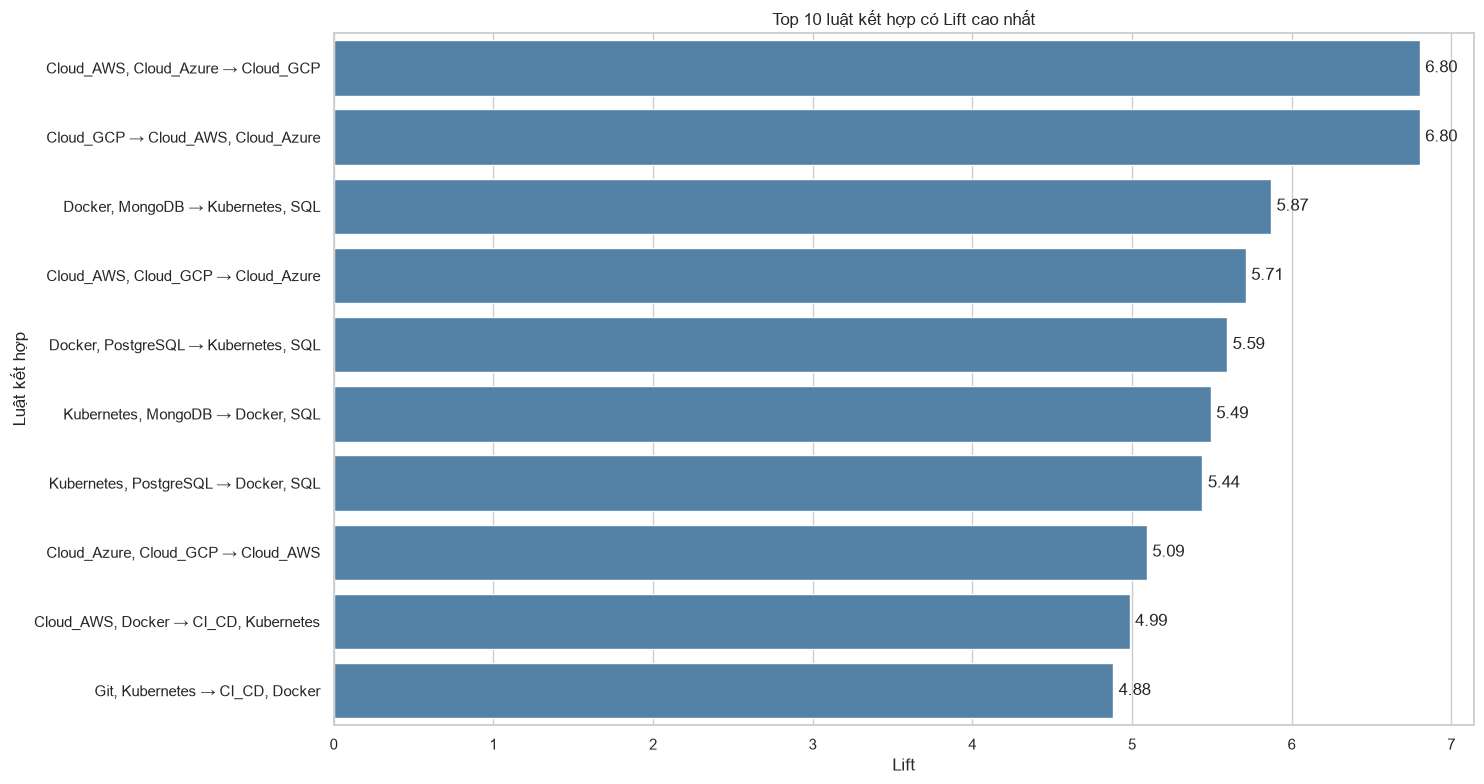

In [39]:
top_rules = rules_display.head(10).copy()

top_rules["Rule"] = (
    top_rules["antecedents"]
    + " → "
    + top_rules["consequents"]
)

plt.figure(figsize=(15, 8))

ax = sns.barplot(
    data=top_rules,
    x="lift",
    y="Rule",
    color="steelblue"
)

ax.bar_label(
    ax.containers[0],
    fmt="%.2f",
    padding=4
)

plt.title("Top 10 luật kết hợp có Lift cao nhất")
plt.xlabel("Lift")
plt.ylabel("Luật kết hợp")
plt.tight_layout()
plt.show()

#### Nhận xét
- Các luật có Lift cao chủ yếu liên quan đến Cloud và DevOps.
- Luật AWS + Azure → GCP có Lift đạt 6,80, cho thấy mối liên kết mạnh giữa các nền tảng Cloud.
- Docker, Kubernetes và hệ quản trị cơ sở dữ liệu có xu hướng xuất hiện cùng nhau.

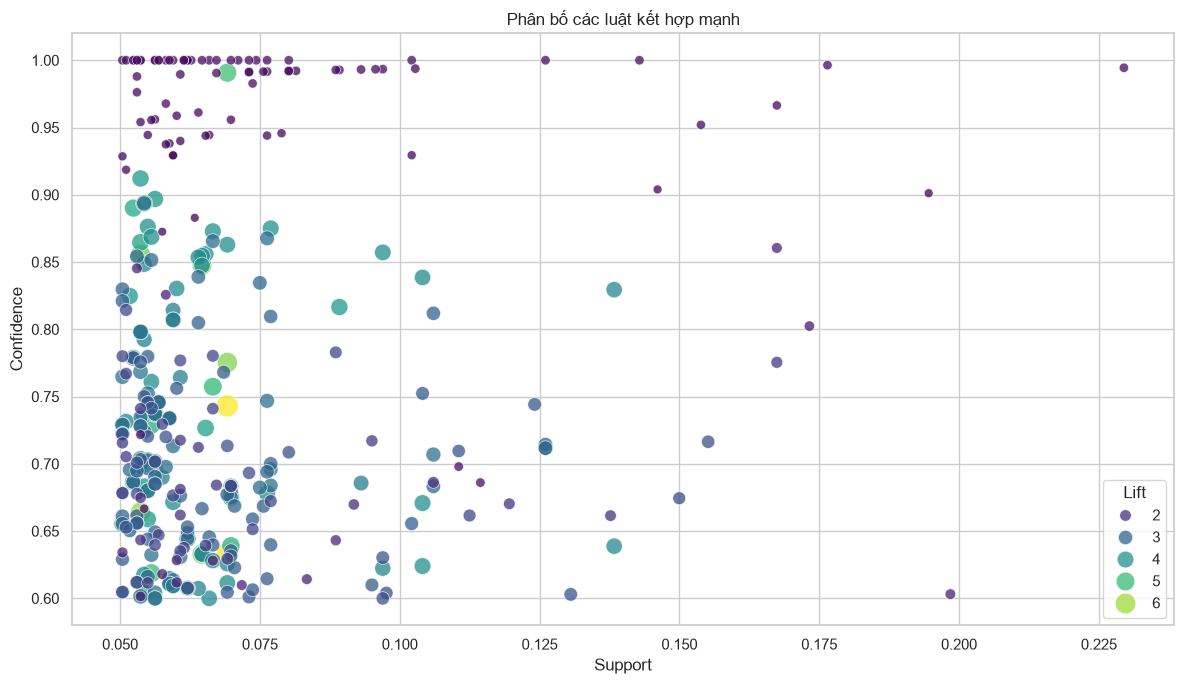

In [40]:
plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=strong_rules,
    x="support",
    y="confidence",
    hue="lift",
    size="lift",
    palette="viridis",
    sizes=(40, 250),
    alpha=0.75
)

plt.title("Phân bố các luật kết hợp mạnh")
plt.xlabel("Support")
plt.ylabel("Confidence")
plt.legend(title="Lift")
plt.tight_layout()
plt.show()


#### Nhận xét
- Các luật được giữ lại có Support từ 5% và Confidence từ 60% trở lên.
- Các điểm có kích thước lớn và màu sắc nổi bật biểu thị những luật có Lift cao.
- Luật có Lift cao không nhất thiết có Support cao, cho thấy mức độ liên kết mạnh không đồng nghĩa với mức độ phổ biến lớn.
-> Kết quả khai phá luật kết hợp cho thấy các kỹ năng Cloud, DevOps và cơ sở dữ liệu có mối liên kết chặt chẽ. Đây là cơ sở tham khảo để xây dựng lộ trình học tập và phát triển kỹ năng nghề nghiệp trong ngành Data.

### 2.4.6. Kiểm chứng các luật kết hợp tiêu biểu

Kiểm chứng mức độ liên kết giữa các tổ hợp kỹ năng
thông qua Support, Confidence và Lift.

In [41]:
def evaluate_rule(antecedents, consequents):

    A = transactions[list(antecedents)].all(axis=1)
    B = transactions[list(consequents)].all(axis=1)

    support_A = A.mean()
    support_B = B.mean()

    support = (A & B).mean()
    confidence = support / support_A
    lift = confidence / support_B

    return {
        "Antecedents": ", ".join(antecedents),
        "Consequents": ", ".join(consequents),
        "Support": support,
        "Confidence": confidence,
        "Lift": lift
    }

In [42]:
target_rules = pd.DataFrame([
    evaluate_rule(
        ["Python", "SQL"],
        ["Machine_Learning"]
    ),
    evaluate_rule(
        ["Docker", "Kubernetes"],
        ["Cloud_AWS"]
    )
])

target_rules["Dat_Nguong"] = (
    (target_rules["Support"] >= 0.05) &
    (target_rules["Confidence"] >= 0.60) &
    (target_rules["Lift"] > 1.2)
)

target_rules.round(4)

,Antecedents,Consequents,Support,Confidence,Lift,Dat_Nguong
0,"Python, SQL",Machine_Learning,0.0582,0.1587,1.0023,False
1,"Docker, Kubernetes",Cloud_AWS,0.0653,0.4720,2.4257,False


#### Nhận xét

- Luật Python + SQL → Machine Learning có Lift gần 1,
  cho thấy mối liên kết giữa các tập kỹ năng không đáng kể.
- Luật Docker + Kubernetes → Cloud AWS có Lift = 2,4257,
  thể hiện mối liên kết dương giữa DevOps và Cloud Computing.
- Cả hai luật chưa đáp ứng đồng thời các ngưỡng Support,
  Confidence và Lift đã lựa chọn.

## 3. Kết luận tổng thể

### Phân tích khám phá dữ liệu (EDA)
- Phân tích 1.547 tin tuyển dụng thuộc 5 nhóm ngành Data.
- Database / Data Platform & Ops có số lượng tin tuyển dụng cao nhất.
- Phân phối mức lương có xu hướng lệch phải.
- SQL và Python là hai kỹ năng phổ biến nhất.

### Phân cụm K-Means
- Phân cụm dữ liệu dựa trên 60 thuộc tính kỹ năng.
- Khảo sát số cụm bằng Elbow Method và Silhouette Score.
- Xây dựng mô hình K-Means với K = 3.
- Xác định ba chân dung nghề nghiệp:
  1. AI & Machine Learning.
  2. General Data & Analytics.
  3. Data Engineering & Infrastructure.

### Khai phá luật kết hợp
- Khai phá 480 tập kỹ năng phổ biến.
- Sinh 454 luật kết hợp với Confidence tối thiểu 60%.
- Lựa chọn các luật có Lift > 1.2.
- Phát hiện mối liên kết nổi bật giữa các kỹ năng
  Cloud Computing, DevOps và cơ sở dữ liệu.

### Hạn chế
- 74,73% tin tuyển dụng không công bố mức lương.
- Các cụm nghề nghiệp vẫn có sự giao thoa về kỹ năng.
- Luật kết hợp thể hiện sự đồng xuất hiện,
  không khẳng định quan hệ nhân quả.